In [1]:
import json 
import logging
import seaborn as sns
import pandas as pd
#import numpy as np
import pathlib 
import copy 

import gamestate


In [2]:
logger = logging.getLogger(__name__)
logging.basicConfig(filename='../output/logs/probs.log', level=logging.INFO)

In [3]:
# use preset vocabulary 
dummy_vocab=["Löwe", "Pfote", "Zoo", "Schrank", "Katze", "Haustier"]
# load instance of gamestate class with preset vocab, target word, load similarity matrix from file if possible
gs = gamestate.GameState(dummy=True, sim_file="../output/exp_sims.npy", dummy_vocab=dummy_vocab, target="Löwe")

randomly chosen target word: Löwe
similarity table of size 6x6 generated
similarity table saved to ../output/exp_sims.npy


In [4]:
# create diagram of listener probabilies given utterance u, speaker probabilities for utterance u; save to file 
def create_L_diagram(word_rows, output_file="../output/plots/L_plot.png"):
    sns.set_theme(style="whitegrid")

    g = sns.catplot(
        data=pd.DataFrame(word_rows), kind="bar",
        x="word", y="prob", hue="prob_type",
        palette="dark", alpha=.6, height=6
    )
    g.despine(left=True)
    g.set_axis_labels("u", "Wahrscheinlichkeit")
    g.legend.set_title("")
    new_labels = ['$L_{lit_{I};P3}$(Löwe|u)', '$L_{lit_{A};P2}$(P3|u)', '$S_{1;P1}$(u|P3,Löwe)']
    for t, l in zip(g._legend.texts, new_labels):
        t.set_text(l)
    sns.move_legend(g, "upper right")
    fig = g.fig
    fig.savefig(output_file) 
    
    return


In [5]:
# create diagram of speaker probabilities for utterance u given each possible imposter identity as well as weighted sum of speaker probabilites 
# given each possible imposter identity 
# save to file

def create_S_diagram(word_rows, output_file="../output/plots/S_plot.png"):
    sns.set_theme(style="whitegrid")

    # Draw a nested barplot by species and sex
    g = sns.catplot(
        data=pd.DataFrame(word_rows), kind="bar",
        x="word", y="prob", hue="prob_type",
        palette="dark", alpha=.6, height=6
    )#
    g.despine(left=True)
    g.set_axis_labels("u", "Wahrscheinlichkeit")
    #g.legend.set_title("")
    new_labels = ['$S_{1;P1}$(u|P2,Löwe)', '$S_{1;P1}$(u|P3,Löwe)', '$S_{1;cert;P1}$(u|Löwe)'] 
    for t, l in zip(g._legend.texts, new_labels):
        t.set_text(l)
    sns.move_legend(g, "upper right")
    fig = g.fig
    fig.savefig(output_file) 
    return 

In [6]:
# get listener and speaker probabilities from agent class instance, save data as json, figs as png files 
def run_experiment(agent, output_folder="../output/e1"):
    pathlib.Path(output_folder).mkdir(parents=True, exist_ok=True) 
    word_rows = []
    word_rows_certain = []
    for u in gs.V:

        t_prob = agent.L0_t(u, gs.TARGET)
        i_prob =  agent.L0_a(u, ("P3",gs.TARGET))
        s1_prob = agent.S1_i_t(u, "P3", gs.TARGET, adversarial=True)

        s1_prob_p2 = agent.S1_i_t(u, "P2", gs.TARGET, adversarial=True)
        s1_prob_p3 = agent.S1_i_t(u, "P3", gs.TARGET, adversarial=True)
        s1_prob_certain = agent.S1_certain(u, gs.TARGET)

        for prob_name, prob in zip(["L0_t", "L0_i", "S1"], [t_prob, i_prob, s1_prob]):
            row_dic = {"word": u, "prob_type": prob_name, "prob": prob}
            word_rows.append(row_dic)    
        for prob_name, prob in zip(["S1_p2", "S1_p3", "S1_certain"], [s1_prob_p2, s1_prob_p3, s1_prob_certain]):
            row_dic = {"word": u, "prob_type": prob_name, "prob": prob}
            word_rows_certain.append(row_dic)

    with open(output_folder + "/l_rows.json", "w") as final:
	    json.dump(word_rows, final) 
    
    with open(output_folder + "/s_rows.json", "w") as final:
	    json.dump(word_rows_certain, final)       
    
    create_L_diagram(word_rows, output_file=output_folder + "/L_plot.png")
    create_S_diagram(word_rows_certain, output_file=output_folder + "/S_plot.png")

    return(word_rows, word_rows_certain)
    

## Experiment 1: Uniforme Priors

In [7]:
# get copy of gamestate so changes to gamestate are not made to each experiment 
gs1 = copy.deepcopy(gs)
# normal instance of agent, no manipulations to priors/similarities 
a1 = gamestate.Speaker_Agent("P1", gs1, logger=logger, alpha=3, t_weight=2, i_weight=1)


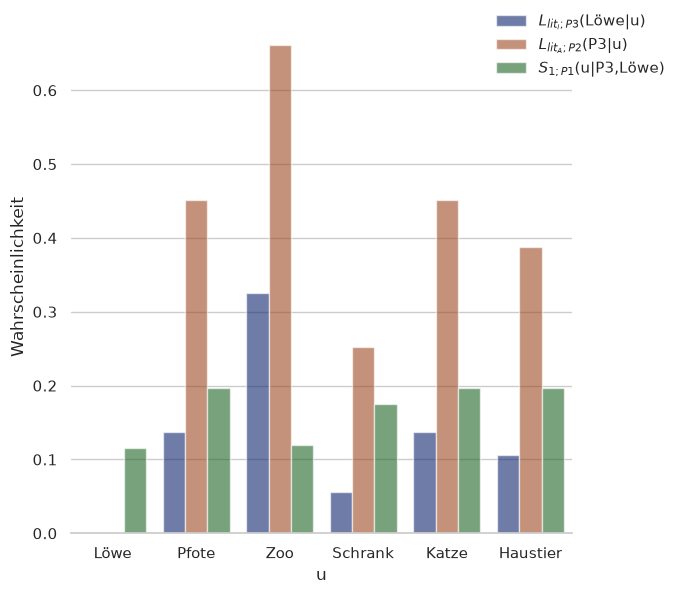

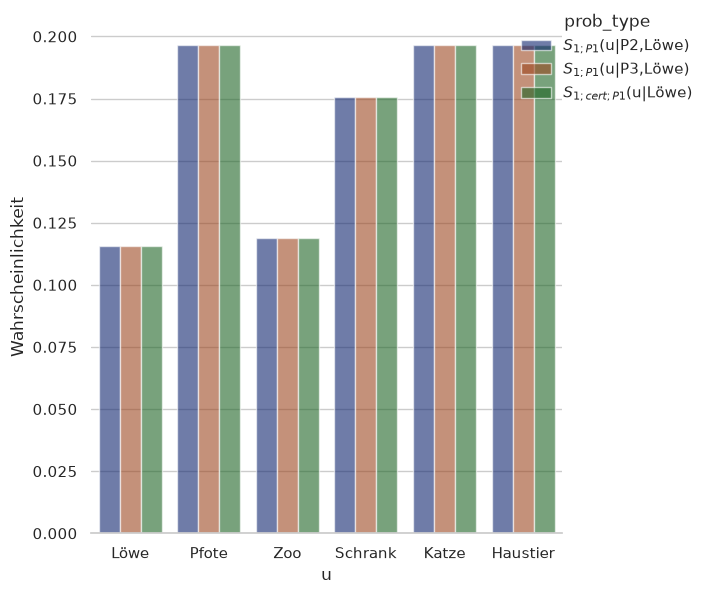

In [8]:
l_probs, s_probs = run_experiment(a1, output_folder="../output/e1")

## Experiment 2: 

In [9]:
gs2 = copy.deepcopy(gs)

a2 = gamestate.Speaker_Agent("P1", gs2, logger=logger, alpha=3, i_weight=1, t_weight=2)
# manipulations to priors 
a2.priors["P1"]["agent"]["i"] = [0, 0.3, 0.7]
a2.priors["P3"]["imposter"]["t"]=[0.2, 0.1, 0.15, 0.05, 0.5, 0]

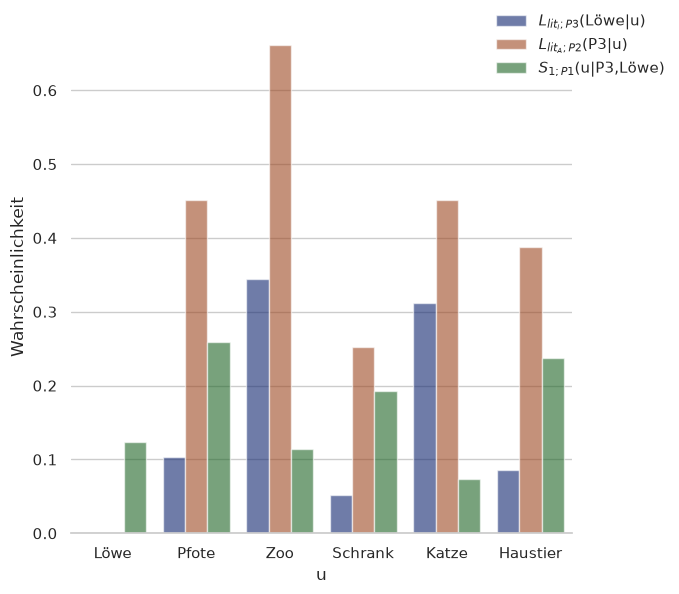

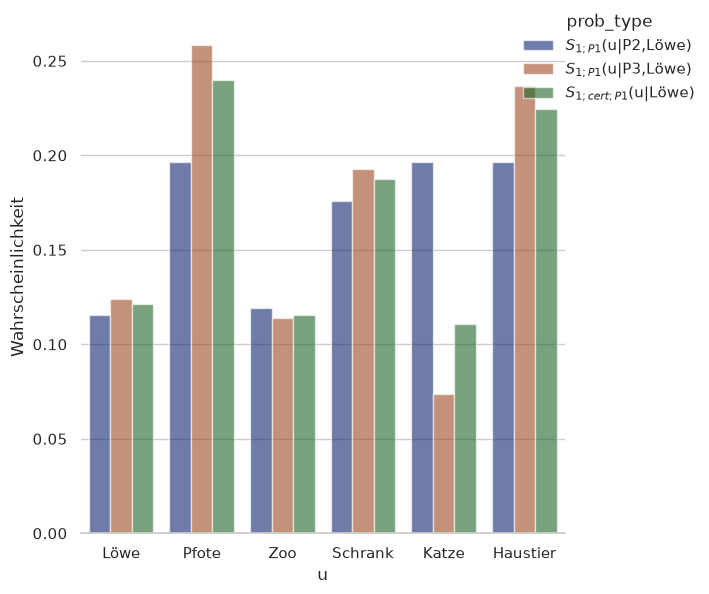

In [10]:
l_probs2, s_probs2 = run_experiment(a2, output_folder="../output/e2")

## Experiment 3 

In [11]:
gs3 = copy.deepcopy(gs)

a3 = gamestate.Speaker_Agent("P1", gs3, alpha=3, logger=logger, i_weight=1, t_weight=2)
a3.priors["P1"]["agent"]["i"] = [0, 0.3, 0.7]
# manipulations to similarities for P2
a3.gs.SIMS["P2"][0][3] = 0.5
a3.gs.SIMS["P2"][3][0] = 0.5


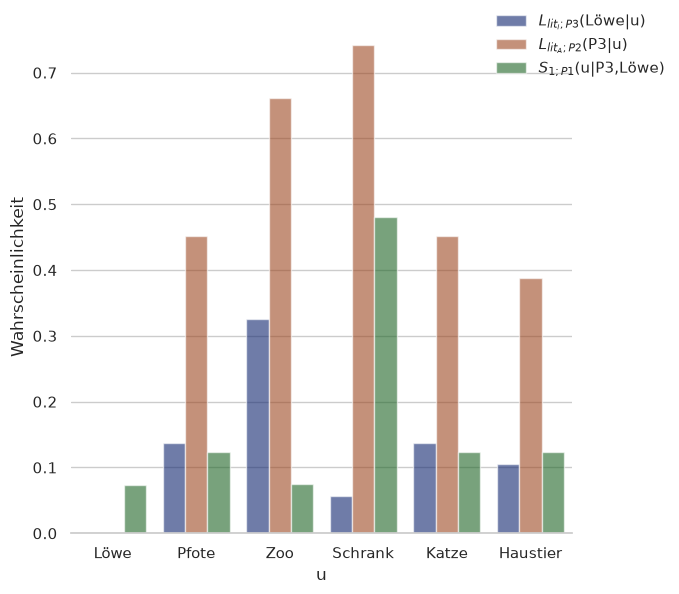

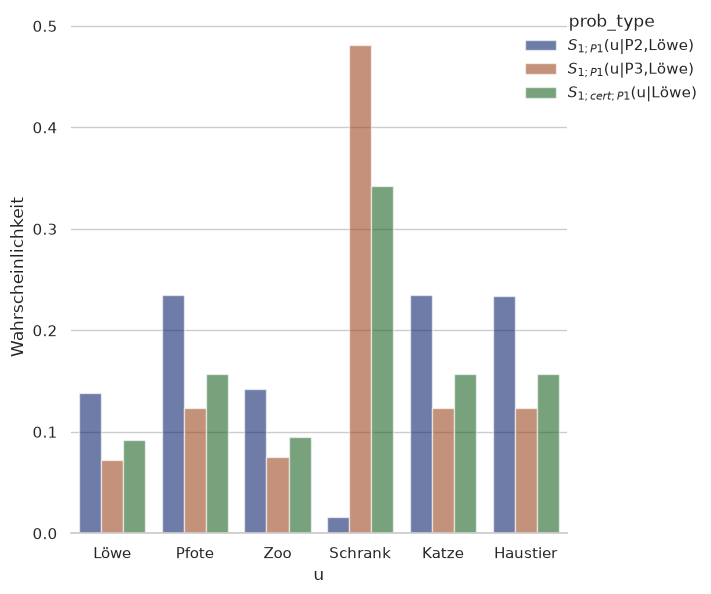

In [12]:
l_probs3, s_probs3 = run_experiment(a3, output_folder="../output/e3")
